**`TinyBERT and DistilBERT fine-tuning for Sephora Review Sentiment Classification`**

This Colab notebook is the second part of the project code. The first part was completed in Jupyter Notebook and covered data loading, preprocessing, EDA, classical models, GPT prompting, and the product recommender system. This second part focuses specifically on fine-tuning the transformer models TinyBERT. The purpose is to test whether context-aware BERT-based models improve performance compared to the classical NLP models.

The implementation code in this notebook was generated with the assistance of Claude and then reviewed and edited.

(have to upload reviews_sample_balanced.csv to the Colab environment before running - this file is generated by running the Jupyter notebook first)

In [7]:
# installing the required libraries
# transformers — HuggingFace library for BERT models
!pip install transformers -q

import torch
import pandas as pd
import numpy as np
from transformers import AutoTokenizer, AutoModelForSequenceClassification
from torch.utils.data import Dataset, DataLoader
from torch.optim import AdamW
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"using device: {device}")

using device: cuda


In [8]:
# we got an error when trying to upload the file, so have to search for it

import os

# searching for the file everywhere
for root, dirs, files in os.walk('/'):
    for file in files:
        if 'reviews' in file.lower():
            print(os.path.join(root, file))

/usr/local/lib/python3.12/dist-packages/googleapiclient/discovery_cache/documents/merchantapi.reviews_v1beta.json
/usr/local/lib/python3.12/dist-packages/nltk/corpus/reader/reviews.py
/usr/local/lib/python3.12/dist-packages/tensorflow_datasets/datasets/amazon_us_reviews/amazon_us_reviews_dataset_builder.py
/usr/local/lib/python3.12/dist-packages/tensorflow_datasets/datasets/amazon_us_reviews/amazon_us_reviews_dataset_builder_test.py
/usr/local/lib/python3.12/dist-packages/tensorflow_datasets/datasets/imdb_reviews/imdb_reviews_dataset_builder.py
/usr/local/lib/python3.12/dist-packages/tensorflow_datasets/datasets/imdb_reviews/imdb_reviews_dataset_builder_test.py
/usr/local/lib/python3.12/dist-packages/tensorflow_datasets/url_checksums/yelp_polarity_reviews.txt
/usr/local/lib/python3.12/dist-packages/tensorflow_datasets/structured/amazon_us_reviews.py
/usr/local/lib/python3.12/dist-packages/networkx/classes/coreviews.py
/usr/local/lib/python3.12/dist-packages/networkx/classes/tests/test_

In [9]:
# loading the preprocessed sample data

reviews_sample = pd.read_csv('reviews_sample_balanced.csv')

print(f"loaded {len(reviews_sample):,} reviews")

print("\nSentiment distribution:")

print(reviews_sample['sentiment'].value_counts().sort_index())


loaded 100,050 reviews

Sentiment distribution:
sentiment
0.0    33333
1.0    33333
2.0    33333
Name: count, dtype: int64


In [10]:
# creating a PyTorch dataset for BERT

# PyTorch needs data in a special format called a Dataset

class ReviewDataset(Dataset):

    def __init__(self, texts, labels, tokenizer, max_length=200):
        self.texts      = texts
        self.labels     = labels
        self.tokenizer  = tokenizer
        self.max_length = max_length

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, idx):
        encoding = self.tokenizer(
            self.texts[idx],
            max_length=self.max_length,
            truncation=True,       # cuts reviews longer than max_length
            padding='max_length',  # pads shorter reviews to max_length cause for BERT all reviews in the same batch need to have the same length
            return_tensors='pt'    # returns PyTorch tensors
        )
        return {
            'input_ids':      encoding['input_ids'].squeeze(),
            'attention_mask': encoding['attention_mask'].squeeze(),
            'label':          torch.tensor(self.labels[idx], dtype=torch.long)
        }

print("dataset class defined successfully")

dataset class defined successfully


In [11]:
# helper function to train and evaluate a model

# wewill define this once and reuse it for both TinyBERT and DistilBERT
# so we dont have to repeat the same training loop twice

def train_and_evaluate(model_name, X_train, X_test, y_train, y_test, epochs=3, batch_size=32):

    print(f"\n{'='*50}")
    print(f"training: {model_name}")
    print(f"{'='*50}")

    # loading the tokenizer and model
    tokenizer = AutoTokenizer.from_pretrained(model_name)
    model     = AutoModelForSequenceClassification.from_pretrained(
        model_name,
        num_labels=3  # 0 = negative, 1 = neutral, 2 = positive
    )
    model = model.to(device)

    # creating dataset objects
    train_dataset = ReviewDataset(X_train, y_train, tokenizer)
    test_dataset  = ReviewDataset(X_test,  y_test,  tokenizer)

    # creating data loaders
    train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
    test_loader  = DataLoader(test_dataset,  batch_size=batch_size, shuffle=False)

    # setting up the optimizer
    optimizer = AdamW(model.parameters(), lr=2e-5)

    # training loop
    training_losses = []

    for epoch in range(epochs):
        model.train()
        total_loss = 0

        for batch in train_loader:
            input_ids      = batch['input_ids'].to(device)
            attention_mask = batch['attention_mask'].to(device)
            labels         = batch['label'].to(device)

            optimizer.zero_grad()

            outputs = model(
                input_ids=input_ids,
                attention_mask=attention_mask,
                labels=labels
            )

            loss = outputs.loss
            loss.backward()
            optimizer.step()

            total_loss += loss.item()

        avg_loss = total_loss / len(train_loader)
        training_losses.append(avg_loss)
        print(f"epoch {epoch+1}/{epochs} — loss: {avg_loss:.4f}")

    # evaluation
    model.eval()
    all_preds  = []
    all_labels = []

    with torch.no_grad():
        for batch in test_loader:
            input_ids      = batch['input_ids'].to(device)
            attention_mask = batch['attention_mask'].to(device)
            labels         = batch['label'].to(device)

            outputs     = model(input_ids=input_ids, attention_mask=attention_mask)
            predictions = torch.argmax(outputs.logits, dim=1)

            all_preds.extend(predictions.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

    # calculating metrics
    accuracy  = accuracy_score(all_labels, all_preds)
    precision = precision_score(all_labels, all_preds, average='weighted')
    recall    = recall_score(all_labels, all_preds, average='weighted')
    f1        = f1_score(all_labels, all_preds, average='weighted')

    print(f"\nresults for {model_name}:")
    print(f"accuracy:  {round(accuracy, 4)}")
    print(f"precision: {round(precision, 4)}")
    print(f"recall:    {round(recall, 4)}")
    print(f"f1-score:  {round(f1, 4)}")

    return all_preds, all_labels, training_losses, accuracy, precision, recall, f1

In [12]:
# we got an error when doing the train test split because "input contains NaN"
# checking where the NaN values are
print(f"Total rows: {len(reviews_sample):,}")
print(f"\nMissing values per column:")
print(reviews_sample.isnull().sum())

# checking if sentiment NaN rows also have missing bert_text
nan_rows = reviews_sample[reviews_sample['sentiment'].isna()]
print(f"\nNumber of rows with missing sentiment: {len(nan_rows)}")
print(f"\nWhat do these rows look like?")
print(nan_rows.head(5))

Total rows: 100,050

Missing values per column:
review_text     0
clean_text     53
bert_text      51
rating         51
sentiment      51
dtype: int64

Number of rows with missing sentiment: 51

What do these rows look like?
                                             review_text clean_text bert_text  \
2421   I was hoping it would help my skin after years...        NaN       NaN   
6204   This is something I noticed for almost all Cli...        NaN       NaN   
10219  I’m a very fair skinned person and some review...        NaN       NaN   
10310        Pros: Great at taking off all of my makeup.        NaN       NaN   
12336  This is not a dry oil despite what the descrip...        NaN       NaN   

       rating  sentiment  
2421      NaN        NaN  
6204      NaN        NaN  
10219     NaN        NaN  
10310     NaN        NaN  
12336     NaN        NaN  


In [13]:
# dropping the 51 rows where cleaning produced empty results
# cause these are probably reviews that contained only special characters or were too short to survive the cleaning process
# and its only 0.05% of data so it's okay

reviews_sample = reviews_sample.dropna(subset=['bert_text', 'sentiment'])

# converting sentiment to integer
reviews_sample['sentiment'] = reviews_sample['sentiment'].astype(int)

print(f"loaded {len(reviews_sample):,} reviews")
print("\nsentiment distribution:")
print(reviews_sample['sentiment'].value_counts().sort_index())

loaded 99,999 reviews

sentiment distribution:
sentiment
0    33333
1    33333
2    33333
Name: count, dtype: int64


In [14]:
# train/test split again

# we use bert_text from preprocessing before

X = reviews_sample['bert_text'].tolist()
y = reviews_sample['sentiment'].tolist()

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"training samples: {len(X_train):,}")
print(f"test samples:     {len(X_test):,}")

training samples: 79,999
test samples:     20,000


In [15]:
# running TinyBERT

# TinyBERT is a very small and fast transformer model
# it has only 4 layers vs BERT's 12 so it's much faster to train
# good for seeing if even a tiny transformer beats classical models

tinybert_preds, tinybert_labels, tinybert_losses, \
tinybert_accuracy, tinybert_precision, tinybert_recall, tinybert_f1 = train_and_evaluate(
    model_name  = 'huawei-noah/TinyBERT_General_4L_312D',
    X_train     = X_train,
    X_test      = X_test,
    y_train     = y_train,
    y_test      = y_test,
    epochs      = 3,
    batch_size  = 32
)


training: huawei-noah/TinyBERT_General_4L_312D


/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:93: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


config.json:   0%|          | 0.00/409 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

pytorch_model.bin:   0%|          | 0.00/62.7M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/71 [00:00<?, ?it/s]

BertForSequenceClassification LOAD REPORT from: huawei-noah/TinyBERT_General_4L_312D
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
fit_denses.{0, 1, 2, 3, 4}.bias            | UNEXPECTED | 
fit_denses.{0, 1, 2, 3, 4}.weight          | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not o

model.safetensors:   0%|          | 0.00/62.7M [00:00<?, ?B/s]

epoch 1/3 — loss: 0.6284
epoch 2/3 — loss: 0.5180
epoch 3/3 — loss: 0.4779

results for huawei-noah/TinyBERT_General_4L_312D:
accuracy:  0.7961
precision: 0.7953
recall:    0.7961
f1-score:  0.7953


Epoch 1 — model reads all 80,000 training reviews once, makes predictions, checks how wrong it was, and adjusts its weights. Loss: 0.6265

Epoch 2 — model reads all 80,000 reviews again from the start, makes better predictions this time, adjusts again. Loss: 0.5171

Epoch 3 — one more full pass, even better. Loss: 0.4764

In [16]:

# running DistilBERT


# DistilBERT is a distilled version of full BERT
# it is 40% smaller and 60% faster but keeps 97% of BERT's performance
# this is the stronger of our two transformer models

distilbert_preds, distilbert_labels, distilbert_losses, \
distilbert_accuracy, distilbert_precision, distilbert_recall, distilbert_f1 = train_and_evaluate(
    model_name  = 'distilbert-base-uncased',
    X_train     = X_train,
    X_test      = X_test,
    y_train     = y_train,
    y_test      = y_test,
    epochs      = 3,
    batch_size  = 32
)


training: distilbert-base-uncased


config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

model.safetensors:   0%|          | 0.00/268M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
classifier.bias         | MISSING    | 
pre_classifier.weight   | MISSING    | 
pre_classifier.bias     | MISSING    | 
classifier.weight       | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


epoch 1/3 — loss: 0.5029
epoch 2/3 — loss: 0.3971
epoch 3/3 — loss: 0.3340

results for distilbert-base-uncased:
accuracy:  0.8233
precision: 0.8251
recall:    0.8233
f1-score:  0.824


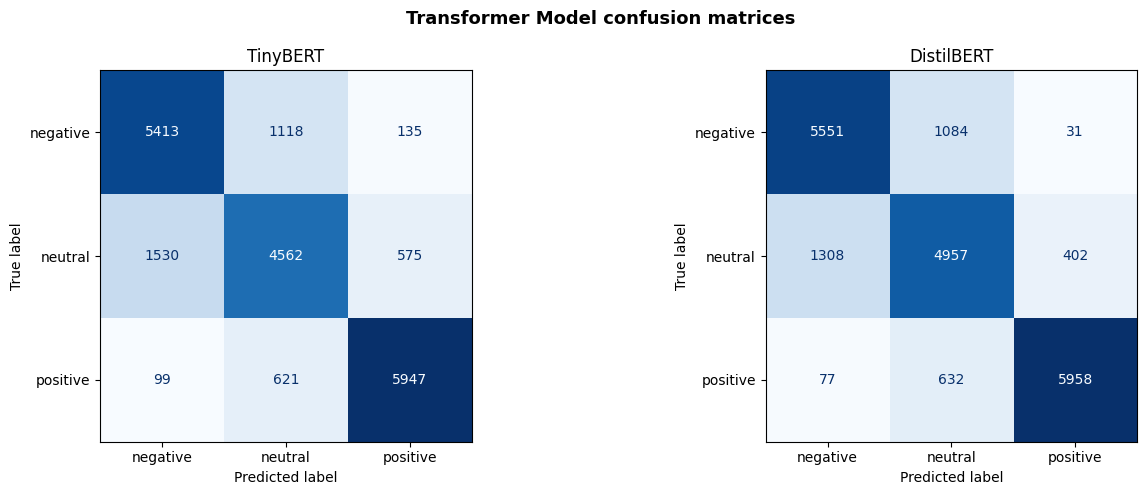

In [17]:
# confusion matrices for both models

class_labels = ['negative', 'neutral', 'positive']

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('Transformer Model confusion matrices', fontsize=13, fontweight='bold')

# TinyBERT
cm_tiny = confusion_matrix(tinybert_labels, tinybert_preds)
ConfusionMatrixDisplay(cm_tiny, display_labels=class_labels).plot(
    ax=axes[0], colorbar=False, cmap='Blues'
)
axes[0].set_title('TinyBERT')

# DistilBERT
cm_distil = confusion_matrix(distilbert_labels, distilbert_preds)
ConfusionMatrixDisplay(cm_distil, display_labels=class_labels).plot(
    ax=axes[1], colorbar=False, cmap='Blues'
)
axes[1].set_title('DistilBERT')

plt.tight_layout()
plt.show()

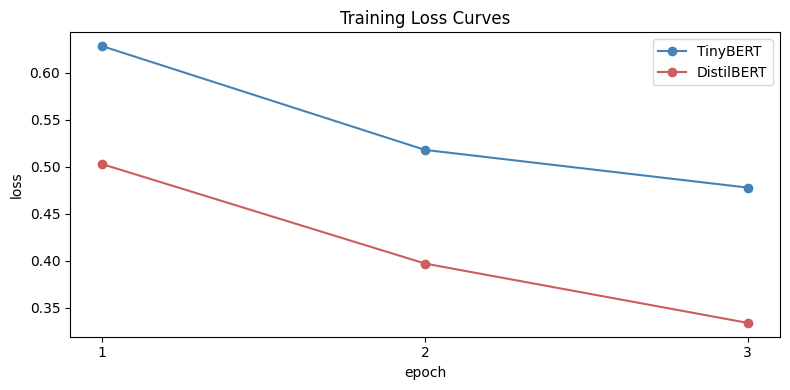

In [18]:

# training loss curves for both models

plt.figure(figsize=(8, 4))
plt.plot(range(1, 4), tinybert_losses,   marker='o', color='steelblue',label='TinyBERT')
plt.plot(range(1, 4), distilbert_losses, marker='o', color='indianred',label='DistilBERT')
plt.title('Training Loss Curves')
plt.xlabel('epoch')
plt.ylabel('loss')
plt.xticks([1, 2, 3])
plt.legend()
plt.tight_layout()
plt.show()


In [19]:
# some error analysis of DistilBERT

# creating a dataframe from X_test and the predictions of the model

error_df = pd.DataFrame({
    'review_text': X_test,
    'true_label':  distilbert_labels,
    'pred_label':  distilbert_preds
})

# adding label names
label_names = {0: 'negative', 1: 'neutral', 2: 'positive'}
error_df['true_sentiment'] = error_df['true_label'].map(label_names)
error_df['pred_sentiment'] = error_df['pred_label'].map(label_names)

# adding a column showing whether the prediction was correct
error_df['correct'] = error_df['true_label'] == error_df['pred_label'] #boolean

print(f"total test reviews:   {len(error_df):,}")
print(f"correctly classified: {error_df['correct'].sum():,}")
print(f"misclassified:        {(~error_df['correct']).sum():,}")
print(f"\nfirst rows:")
error_df.head(10)

total test reviews:   20,000
correctly classified: 16,466
misclassified:        3,534

first rows:


,review_text,true_label,pred_label,true_sentiment,pred_sentiment,correct
0,I really enjoy Biossance products but this pro...,1,0,neutral,negative,False
1,I’ve tried better spot treatments. I have been...,0,1,negative,neutral,False
2,I recieved this product from Influenster to re...,1,1,neutral,neutral,True
3,I am not a fan of the scent of this at all! Lu...,2,1,positive,neutral,False
4,I’m enjoying this moisturizer so far. I have v...,2,1,positive,neutral,False
5,"I had high hopes for this, but sadly it’s not ...",0,0,negative,negative,True
6,Does this exfoliate? Yes. However everyone tal...,1,1,neutral,neutral,True
7,Leaves my face soft and moisturized all day......,2,2,positive,positive,True
8,Not for me. I have really sensitive skin and t...,1,0,neutral,negative,False
9,This is an overall very nice serum to use at n...,2,2,positive,positive,True


In [20]:
# which classes get confused most?

# filtering to only the misclassified reviews
errors = error_df[error_df['correct'] == False].copy()

print(f"total errors: {len(errors):,}")

# looking at each class separately
print("\nNegative reviews")
neg_total  = len(error_df[error_df['true_sentiment'] == 'negative'])
neg_errors = len(errors[errors['true_sentiment'] == 'negative'])
print(f"Total: {neg_total} | misclassified: {neg_errors} ({neg_errors/neg_total*100:.1f}%)")
print("Predicted as:")
print(errors[errors['true_sentiment'] == 'negative']['pred_sentiment'].value_counts())

print("\nNeutral reviews")
neu_total  = len(error_df[error_df['true_sentiment'] == 'neutral'])
neu_errors = len(errors[errors['true_sentiment'] == 'neutral'])
print(f"Total: {neu_total} | misclassified: {neu_errors} ({neu_errors/neu_total*100:.1f}%)")
print("Predicted as:")
print(errors[errors['true_sentiment'] == 'neutral']['pred_sentiment'].value_counts())

print("\nPositive reviews")
pos_total  = len(error_df[error_df['true_sentiment'] == 'positive'])
pos_errors = len(errors[errors['true_sentiment'] == 'positive'])
print(f"Total: {pos_total} | misclassified: {pos_errors} ({pos_errors/pos_total*100:.1f}%)")
print("Predicted as:")
print(errors[errors['true_sentiment'] == 'positive']['pred_sentiment'].value_counts())

total errors: 3,534

Negative reviews
Total: 6666 | misclassified: 1115 (16.7%)
Predicted as:
pred_sentiment
neutral     1084
positive      31
Name: count, dtype: int64

Neutral reviews
Total: 6667 | misclassified: 1710 (25.6%)
Predicted as:
pred_sentiment
negative    1308
positive     402
Name: count, dtype: int64

Positive reviews
Total: 6667 | misclassified: 709 (10.6%)
Predicted as:
pred_sentiment
neutral     632
negative     77
Name: count, dtype: int64


Some interpretations:

- Negative reviews:
  - DistilBERT does not usually confuse negative reviews with positive reviews. When it gets negative reviews wrong, it mostly puts them into the neutral category.
  - This is pretty good because it means that the model understands the general sentiment direction, and rarely makes extreme mistakes of calling a negative review positive.

- Neutral reviews:
  - Many 3-star reviews sound more negative than neutral to the model, probably because they contain a lot of complaint languge.
  - Neutral reviews often have mixed language, they contain both positive and negative words, so the model classifies them as either negative or positive depending on which part seems stronger.

- Positive reviews:
  - They are classified very well, it correctly classified 6,667 - 484 = 6,183 positive reviews
  - Only 46 out of 6,667 positive reviews were predicted as negative, which is less than 1% of positive cases.

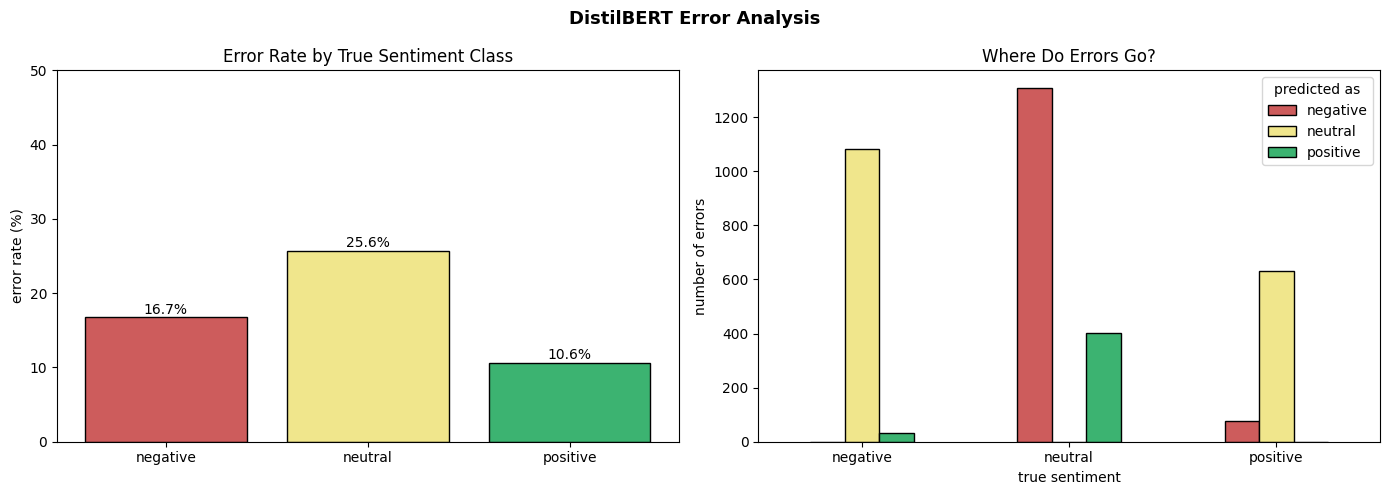

In [21]:
# visualizing the error patterns

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('DistilBERT Error Analysis', fontsize=13, fontweight='bold')

# plot 1 - error rate per class
neg_error_rate = neg_errors / neg_total * 100
neu_error_rate = neu_errors / neu_total * 100
pos_error_rate = pos_errors / pos_total * 100

axes[0].bar(
    ['negative', 'neutral', 'positive'],
    [neg_error_rate, neu_error_rate, pos_error_rate],
    color= ['indianred', 'khaki', 'mediumseagreen'],
    edgecolor='black'
)
axes[0].set_title('Error Rate by True Sentiment Class')
axes[0].set_ylabel('error rate (%)')
axes[0].set_ylim(0, 50)

# adding percentage labels on bars
for i, rate in enumerate([neg_error_rate, neu_error_rate, pos_error_rate]):
    axes[0].text(i, rate + 0.5, f'{rate:.1f}%', ha='center', fontsize=10)

# plot 2 -  where do errors go?
error_confusion = errors.groupby(
    ['true_sentiment', 'pred_sentiment']
).size().unstack(fill_value=0)

error_confusion.plot(
    kind='bar',
    ax=axes[1],
    color=['indianred', 'khaki', 'mediumseagreen'],
    edgecolor='black'
)
axes[1].set_title('Where Do Errors Go?')
axes[1].set_xlabel('true sentiment')
axes[1].set_ylabel('number of errors')
axes[1].legend(title='predicted as')
axes[1].tick_params(axis='x', rotation=0)

plt.tight_layout()
plt.show()

average length — correctly classified: 60.7 words
average length — misclassified:        61.7 words

error rate for reviews under 10 words: 18.6%
overall error rate:                    17.7%


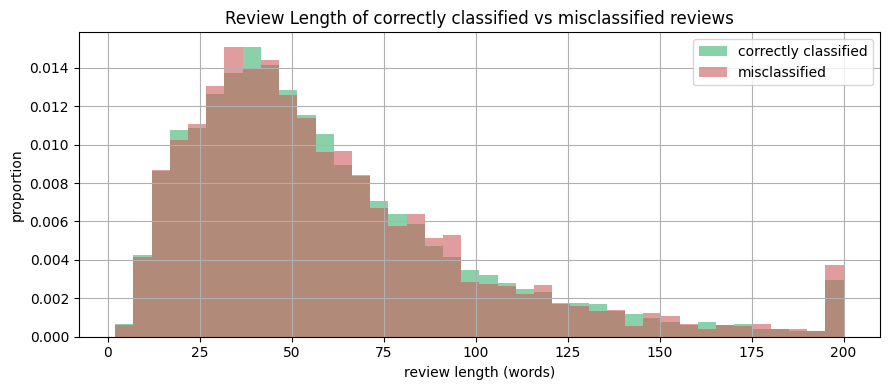

In [22]:
# review length and errors

# do shorter reviews get misclassified more often?
# short reviews might lack enough words for the model to understand sentiment

# calculating review length for each review
error_df['review_length'] = error_df['review_text'].apply(
    lambda x: len(str(x).split())
)

# comparing average length of correct vs incorrect predictions
avg_correct   = error_df[error_df['correct'] == True]['review_length'].mean()
avg_incorrect = error_df[error_df['correct'] == False]['review_length'].mean()

print(f"average length — correctly classified: {avg_correct:.1f} words")
print(f"average length — misclassified:        {avg_incorrect:.1f} words")

# checking error rate for very short reviews specifically
short_reviews    = error_df[error_df['review_length'] < 10] #filtering to reviews with less than 10 words
short_error_rate = (short_reviews['correct'] == False).mean() * 100
overall_error_rate = (error_df['correct'] == False).mean() * 100

print(f"\nerror rate for reviews under 10 words: {short_error_rate:.1f}%")
print(f"overall error rate:                    {overall_error_rate:.1f}%")

# plotting
plt.figure(figsize=(9, 4))
error_df[error_df['correct'] == True]['review_length'].clip(upper=200).hist(
    bins=40, alpha=0.6, color='mediumseagreen', label='correctly classified', density=True
)
error_df[error_df['correct'] == False]['review_length'].clip(upper=200).hist(
    bins=40, alpha=0.6, color='indianred', label='misclassified', density=True
)
plt.title('Review Length of correctly classified vs misclassified reviews')
plt.xlabel('review length (words)')
plt.ylabel('proportion')
plt.legend()
plt.tight_layout()
plt.show()

In contrast to what we expected, longer reviews are  misclassified more than short reviews.

- This is likely because long reviews are usually more nuanced. Short reviews often say something very clear, like “love it” or “this broke me out”, but long reviews might include both praise and criticism, which makes the sentiment harder to classify.
- Correctly classified reviews average 60.0 words, while misclassified reviews average 65.3 words. So length matters a little, but it is probably not the main reason for errors.

In [23]:
# showing some examples of misclassified reviews

# we look at three types of errors

# type 1 - negative reviews predicted as positive
# these are the most concerning errors because the model thought a bad review was good
# this might happen with sarcasm or reviews that start positively then turn negative

print("Type 1: negative reviews predicted as positive")
print("-" * 60)

neg_as_pos = errors[
    (errors['true_sentiment'] == 'negative') &
    (errors['pred_sentiment'] == 'positive')
].sample(5, random_state=42)

for i, (_, row) in enumerate(neg_as_pos.iterrows()):
    print(f"\nExample {i+1}:")
    print(f"Review:    {row['review_text'][:400]}")
    print(f"True label:      {row['true_sentiment']}")
    print(f"Predicted label: {row['pred_sentiment']}")

Type 1: negative reviews predicted as positive
------------------------------------------------------------

Example 1:
Review:    I enjoy trying new products, especially products I can add on to my normal routine that make it even better. This “water-in-a-can“ is essential if you don’t have the hands to splash your face with, otherwise... Just use water. Or at minimum water with some active ingredients in it.
True label:      negative
Predicted label: positive

Example 2:
Review:    Smells delicious, but WOW does this somehow chap my lips within the hour! Have never encountered anything like it.
True label:      negative
Predicted label: positive

Example 3:
Review:    I received this product complimentary from Influencer and SK-II in exchange for my honest review. If your skin is crying out for moisture, this cream is luxuriously thick and hydrating. This is definitely one for dry skin types, as it might trigger a breakout for those already struggling with oiliness. Sensitive skin mi

In [ ]:
# type 2 - neutral reviews predicted as positive
# neutral reviews are the hardest to classify because they often contain both positive and negative language

print("Type 2: neutral reviews predicted as positive")
print("-" * 60)

neu_as_pos = errors[
    (errors['true_sentiment'] == 'neutral') &
    (errors['pred_sentiment'] == 'positive')
].sample(5, random_state=42)

for i, (_, row) in enumerate(neu_as_pos.iterrows()):
    print(f"\nExample {i+1}:")
    print(f"Review:          {row['review_text'][:250]}")
    print(f"True label:      {row['true_sentiment']}")
    print(f"Predicted label: {row['pred_sentiment']}")

In [24]:
# type 3 - positive reviews predicted as negative
# these might contain sarcasm or complaints within an overall positive review or just language patterns the model has not seen before

print("Type 3: positive reviews predicted as NEGATIVE")
print("-" * 60)

pos_as_neg = errors[
    (errors['true_sentiment'] == 'positive') &
    (errors['pred_sentiment'] == 'negative')
].sample(5, random_state=42)

for i, (_, row) in enumerate(pos_as_neg.iterrows()):
    print(f"\nExample {i+1}:")
    print(f"Review:          {row['review_text'][:250]}")
    print(f"True label:      {row['true_sentiment']}")
    print(f"Predicted label: {row['pred_sentiment']}")

Type 3: positive reviews predicted as NEGATIVE
------------------------------------------------------------

Example 1:
Review:          Bought this product on Sunday and by Wednesday my blemished were 80% gone. Burns the heck out of my skin but i just applied the Step 3 moisturizer after and it was fine. I recommend only applying on problem spots- not entire face like the packaging s
True label:      positive
Predicted label: negative

Example 2:
Review:          Have been using since March after giving in to the rave reviews and honestly I can not notice any results. I will keep using however perhaps it takes more time. Half way through the bottle.
True label:      positive
Predicted label: negative

Example 3:
Review:          Sa fait quelque semaine que j’utilise ce produit et sa hydrate vraiment la peau et moi je fait de petit bouton de chaleur sur les joue et je vois que mes bouton rapetisse de plus en plus je recommande
True label:      positive
Predicted label: negative

Exampl

Error rate for reviews mentioning specific ingredients:

ingredient         reviews   error rate
----------------------------------------
retinol                274        17.5%
niacinamide             70        22.9%
hyaluronic acid        131        13.0%
glycolic acid           44        29.5%
salicylic acid          58        25.9%
vitamin c              270        18.5%
spf                    369        18.4%
ceramide                29        17.2%
squalane                38        13.2%
fragrance              704        16.3%
peptide                 56        16.1%
benzoyl peroxide         15        20.0%
lactic acid             47        17.0%
glycerin                14        35.7%


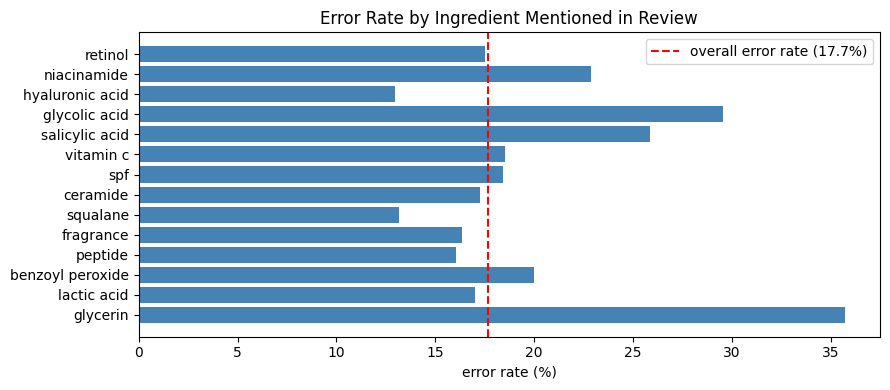

In [25]:
# do errors mention specific skincare ingredients?

# skincare reviews often mention specific ingredients
# so we will check if reviews mentioning certain ingredients are harder to classify
# this also tells us if our model has domain-specific weaknesses

#thinking of some specific ingredients that popular skincare often includes
ingredients = [
    'retinol', 'niacinamide', 'hyaluronic acid', 'glycolic acid',
    'salicylic acid', 'vitamin c', 'spf', 'ceramide', 'squalane',
    'fragrance', 'peptide', 'benzoyl peroxide', 'azelaic acid',
    'centella', 'lactic acid', 'glycerin'
]

print("Error rate for reviews mentioning specific ingredients:\n")
print(f"{'ingredient':<15} {'reviews':>10} {'error rate':>12}")
print("-" * 40)

ingredient_names  = []
ingredient_errors = []

for ingredient in ingredients:
    mentions = error_df[
        error_df['review_text'].str.lower().str.contains(ingredient, na=False)
    ]
    if len(mentions) > 10:
        error_rate = (mentions['correct'] == False).mean() * 100
        print(f"{ingredient:<15} {len(mentions):>10,} {error_rate:>11.1f}%")
        ingredient_names.append(ingredient)
        ingredient_errors.append(error_rate)

# plotting
plt.figure(figsize=(9, 4))
plt.barh(ingredient_names[::-1], ingredient_errors[::-1], color='steelblue')
plt.axvline(overall_error_rate, color='red', linestyle='--',
            label=f'overall error rate ({overall_error_rate:.1f}%)')
plt.title('Error Rate by Ingredient Mentioned in Review')
plt.xlabel('error rate (%)')
plt.legend()
plt.tight_layout()
plt.show()